# Supplementary Figure S7 — SEM host-interaction diagnostic

Standalone workflow for the four diagnostic melt inclusions and their individual measured-host ±5% sensitivity vectors. The Science Advances requirements from `Nov6_AllFigures/00_Setup` are written explicitly below.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from IPython.display import display

# Select the folder containing the three supplemental workbooks.
DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

# Find Nov6_AllFigures from the current working directory.
PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S07_SEM_Host_Interactions'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S07_SEM_Host_Interactions_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

DATA_PATH = WORKBOOK_PATHS['S1']
DATA_SHEET = 'MI_Hosts_Plag_Pxy'

# Science Advances settings copied from Nov6_AllFigures/00_Setup.
SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_INTERMEDIATE_WIDTH_IN = 5.67
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8

BASE_TEXT_SIZE_PT = 8.0
AXIS_LABEL_SIZE_PT = 8.0
TITLE_SIZE_PT = 8.0
TICK_LABEL_SIZE_PT = 8.0
LEGEND_SIZE_PT = 8.0
LEGEND_TITLE_SIZE_PT = 8.0
ANNOTATION_SIZE_PT = 8.0
MINIMUM_TEXT_SIZE_PT = 6.0
HIGHLIGHT_LABEL_SIZE_PT = 6.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 5.40

PUBLICATION_FONT = 'Arial'
INSTALLED_FONT_NAMES = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in INSTALLED_FONT_NAMES:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': AXIS_LABEL_SIZE_PT,
    'axes.titlesize': TITLE_SIZE_PT,
    'xtick.labelsize': TICK_LABEL_SIZE_PT,
    'ytick.labelsize': TICK_LABEL_SIZE_PT,
    'legend.fontsize': LEGEND_SIZE_PT,
    'legend.title_fontsize': LEGEND_TITLE_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'mathtext.fontset': 'custom',
    'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic',
    'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'mathtext.bfit': f'{PUBLICATION_FONT}:bold:italic',
    'mathtext.fallback': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

SAMPLE_COLORS = {
    '74D': '#F4A261',
    '74A': '#D55E00',
    '75': '#56B4E9',
    '76A': '#0072B2',
}
PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PEC_MINUS_COLOR = 'purple'
PEC_PLUS_COLOR = 'gray'
HIGHLIGHT_IDS = {
    '74A_C23_MI3',
    '74A_C6_MI1',
    '76A_C31_MI1',
    '74D_C48_MI1',
}
HIGHLIGHT_COLOR = '#D62728'
HIGHLIGHT_CODES = {
    '74A_C6_MI1': '1',
    '74A_C23_MI3': '2',
    '74D_C48_MI1': '3',
    '76A_C31_MI1': '4',
}
HIGHLIGHT_CODE_OFFSETS = {
    '74A_C6_MI1': (3, 3),
    '74A_C23_MI3': (3, 3),
    '74D_C48_MI1': (3, 6),
    '76A_C31_MI1': (-9, -9),
}

print('Figure directory:', FIGURE_DIRECTORY)
print('Source:', DATA_PATH, '/', DATA_SHEET)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S07_SEM_Host_Interactions
Source: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20/Dechert_S1_AllData.xlsx / MI_Hosts_Plag_Pxy
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 5.4 in


## Figure S7-specific source preparation

The four named discarded diagnostic inclusions are reconstructed in memory from their retained raw ten-oxide SEM measurements and normalized to 100 wt%. The public source workbook remains unchanged. No missing values are replaced and no SIMS or trace-element filters are applied.

In [2]:
df_source = pd.read_excel(DATA_PATH, sheet_name=DATA_SHEET)
df_pec = df_source.copy()

OXIDE_NAMES = [
    'SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MnO',
    'MgO', 'CaO', 'Na2O', 'K2O', 'P2O5',
]
glass_cols = {oxide: f'{oxide}_SEMGlass' for oxide in OXIDE_NAMES}
host_cols = {oxide: f'{oxide}_host' for oxide in OXIDE_NAMES}

glass_oxide_sources = {
    oxide: f'{oxide}_SEMGlass_AnhydoNorm'
    for oxide in ['SiO2', 'TiO2', 'Al2O3', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O', 'P2O5']
}
glass_oxide_sources['FeOt'] = 'FeOtt_SEMGlass_AnhydoNorm'

# Reconstruct only the four explicitly selected diagnostic glasses.
focus_mask = df_pec['base_name'].isin(HIGHLIGHT_IDS)
raw_sources = {
    oxide: f"{'FeOtt' if oxide == 'FeOt' else oxide}_SEMGlass_Raw"
    for oxide in OXIDE_NAMES
}
raw_focus = df_pec.loc[focus_mask, list(raw_sources.values())].apply(pd.to_numeric, errors='coerce')
if not raw_focus.notna().all().all():
    raise ValueError('A diagnostic raw oxide is missing.')
raw_totals = raw_focus.sum(axis=1)
if not raw_totals.gt(0).all():
    raise ValueError('A diagnostic raw-oxide total is not positive.')
normalized_focus = raw_focus.div(raw_totals, axis=0) * 100

for oxide, raw_column in raw_sources.items():
    df_pec.loc[focus_mask, glass_oxide_sources[oxide]] = normalized_focus[raw_column]

required_source_cols = ['base_name', 'mineral_phase', *glass_oxide_sources.values(), *host_cols.values()]
missing_source_cols = [column for column in required_source_cols if column not in df_pec.columns]
if missing_source_cols:
    raise KeyError(f'Missing source fields required for PEC plotting: {missing_source_cols}')

glass_aliases = {
    glass_cols[oxide]: pd.to_numeric(df_pec[source], errors='coerce')
    for oxide, source in glass_oxide_sources.items()
}
df_pec = pd.concat([df_pec, pd.DataFrame(glass_aliases, index=df_pec.index)], axis=1)
for column in host_cols.values():
    df_pec[column] = pd.to_numeric(df_pec[column], errors='coerce')

df_pec['mineral_phase'] = df_pec['mineral_phase'].replace({'opx': 'pxy'})

# Assign sample keys explicitly from the beginning of each base_name.
sample_keys = []
for base_name in df_pec['base_name']:
    sample_key = None
    for candidate_key in SAMPLE_COLORS:
        if str(base_name).startswith(candidate_key):
            sample_key = candidate_key
            break
    sample_keys.append(sample_key)
df_pec['sample_key'] = sample_keys

mask_matrix = df_pec['base_name'].astype('string').str.contains('MTX', na=False)
mask_non_matrix = ~mask_matrix
mask_has_host_glass = mask_non_matrix.copy()
for oxide in OXIDE_NAMES:
    mask_has_host_glass &= df_pec[glass_cols[oxide]].notna() & df_pec[host_cols[oxide]].notna()

pec_work = df_pec.loc[mask_has_host_glass].copy()
focus_work = pec_work.loc[pec_work['base_name'].isin(HIGHLIGHT_IDS)].copy()
matrix_rows = df_pec.loc[mask_matrix].copy()

source_count_rows = [
    {'scope': 'workbook', 'sample_key': 'All', 'mineral_phase': 'All', 'count': len(df_source)},
    {'scope': 'matrix_context', 'sample_key': 'All', 'mineral_phase': 'matrix', 'count': int(mask_matrix.sum())},
    {'scope': 'non_matrix_source', 'sample_key': 'All', 'mineral_phase': 'All', 'count': int(mask_non_matrix.sum())},
    {'scope': 'complete_10_oxide_PEC', 'sample_key': 'All', 'mineral_phase': 'All', 'count': len(pec_work)},
]
for (sample, phase), count in focus_work.groupby(['sample_key', 'mineral_phase'], dropna=False).size().items():
    source_count_rows.append({
        'scope': 'complete_10_oxide_PEC',
        'sample_key': sample,
        'mineral_phase': phase,
        'count': int(count),
    })
source_counts = pd.DataFrame(source_count_rows)
SOURCE_COUNTS_PATH = OUTPUT_DIRECTORY / 'Figure_S07_SEM_Host_Interactions_Source_Counts.csv'
source_counts.to_csv(SOURCE_COUNTS_PATH, index=False)

print('Source rows:', len(df_source))
print('Matrix-glass rows excluded from vectors:', len(matrix_rows))
print('Complete non-matrix ten-oxide PEC rows:', len(pec_work))
print('Diagnostic PEC rows:', len(focus_work))
display(source_counts)

Source rows: 212
Matrix-glass rows excluded from vectors: 13
Complete non-matrix ten-oxide PEC rows: 121
Diagnostic PEC rows: 4


,scope,sample_key,mineral_phase,count
0,workbook,All,All,212
1,matrix_context,All,matrix,13
2,non_matrix_source,All,All,199
3,complete_10_oxide_PEC,All,All,121
4,complete_10_oxide_PEC,74A,plag,1
5,complete_10_oxide_PEC,74A,pxy,1
6,complete_10_oxide_PEC,74D,pxy,1
7,complete_10_oxide_PEC,76A,pxy,1


## Figure S7

Each diagnostic vector is calculated at exactly `x = -0.05, 0, +0.05` using `x × host + (1 − x) × measured glass`. These endpoints are a visual sensitivity test, not formal PEC corrections.

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S07_SEM_Host_Interactions/Figure_S07_SEM_Host_Interactions_Final/Figure_S07_SEM_Host_Interactions.pdf


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S07_SEM_Host_Interactions/Figure_S07_SEM_Host_Interactions_Final/Figure_S07_SEM_Host_Interactions.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S07_SEM_Host_Interactions/Figure_S07_SEM_Host_Interactions_Final/Figure_S07_SEM_Host_Interactions.svg


,panel,phase,x_oxide,y_oxide,sample_key,eligible_vector_count,finite_matrix_context_count
4,A,plag,SiO2,Al2O3,All,4,0
9,B,plag,SiO2,CaO,All,4,0
14,C,plag,SiO2,Na2O,All,4,0
19,D,plag,SiO2,FeOt,All,4,0
24,E,pxy,MgO,FeOt,All,4,0
29,F,pxy,MgO,CaO,All,4,0
34,G,pxy,MgO,Al2O3,All,4,0
39,H,pxy,MgO,SiO2,All,4,0


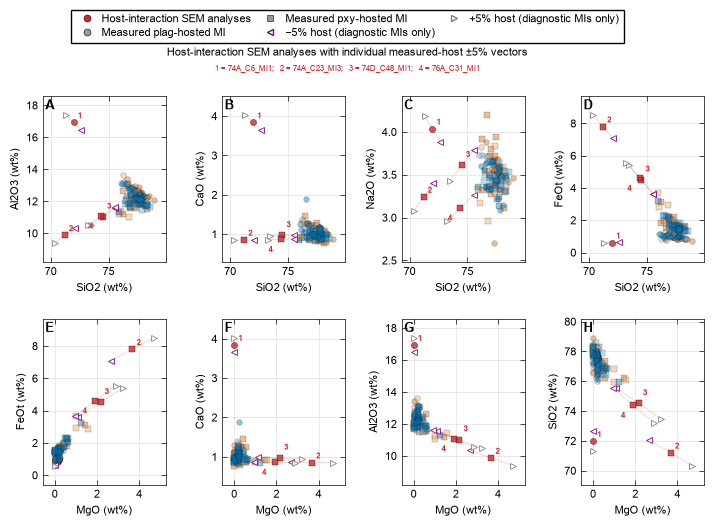

In [3]:
PANEL_SPECS = [
    {'panel': 'A', 'row': 0, 'col': 0, 'phase': 'plag', 'x_oxide': 'SiO2', 'y_oxide': 'Al2O3'},
    {'panel': 'B', 'row': 0, 'col': 1, 'phase': 'plag', 'x_oxide': 'SiO2', 'y_oxide': 'CaO'},
    {'panel': 'C', 'row': 0, 'col': 2, 'phase': 'plag', 'x_oxide': 'SiO2', 'y_oxide': 'Na2O'},
    {'panel': 'D', 'row': 0, 'col': 3, 'phase': 'plag', 'x_oxide': 'SiO2', 'y_oxide': 'FeOt'},
    {'panel': 'E', 'row': 1, 'col': 0, 'phase': 'pxy', 'x_oxide': 'MgO', 'y_oxide': 'FeOt'},
    {'panel': 'F', 'row': 1, 'col': 1, 'phase': 'pxy', 'x_oxide': 'MgO', 'y_oxide': 'CaO'},
    {'panel': 'G', 'row': 1, 'col': 2, 'phase': 'pxy', 'x_oxide': 'MgO', 'y_oxide': 'Al2O3'},
    {'panel': 'H', 'row': 1, 'col': 3, 'phase': 'pxy', 'x_oxide': 'MgO', 'y_oxide': 'SiO2'},
]
PEC_FRACTIONS = (-0.05, 0.0, 0.05)

figure, axes = plt.subplots(
    2,
    4,
    figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN),
    constrained_layout=False,
)
panel_count_rows = []
vector_value_rows = []

for spec in PANEL_SPECS:
    axis = axes[spec['row'], spec['col']]
    x_oxide = spec['x_oxide']
    y_oxide = spec['y_oxide']
    plot_rows = focus_work.copy()
    reference_rows = pec_work.loc[~pec_work['base_name'].isin(HIGHLIGHT_IDS)].copy()

    # All other eligible non-matrix MIs are context points only.
    for _, reference in reference_rows.iterrows():
        axis.scatter(
            reference[glass_cols[x_oxide]],
            reference[glass_cols[y_oxide]],
            marker=PHASE_MARKERS[reference['mineral_phase']],
            facecolor=SAMPLE_COLORS.get(reference['sample_key'], '0.5'),
            edgecolor='black',
            linewidth=0.28,
            s=16,
            alpha=0.42,
            zorder=1,
        )

    # Only the four diagnostic inclusions receive vectors and labels.
    for _, row in plot_rows.iterrows():
        sample = row['sample_key']
        color = HIGHLIGHT_COLOR
        marker = PHASE_MARKERS[row['mineral_phase']]
        values = {}

        for fraction in PEC_FRACTIONS:
            x_value = fraction * row[host_cols[x_oxide]] + (1 - fraction) * row[glass_cols[x_oxide]]
            y_value = fraction * row[host_cols[y_oxide]] + (1 - fraction) * row[glass_cols[y_oxide]]
            values[fraction] = (x_value, y_value)
            vector_value_rows.append({
                'panel': spec['panel'],
                'base_name': row['base_name'],
                'sample_key': sample,
                'mineral_phase': row['mineral_phase'],
                'fraction_host': fraction,
                'x_oxide': x_oxide,
                'y_oxide': y_oxide,
                'x_value': x_value,
                'y_value': y_value,
            })

        x_minus, y_minus = values[-0.05]
        x_measured, y_measured = values[0.0]
        x_plus, y_plus = values[0.05]

        axis.plot(
            [x_minus, x_measured, x_plus],
            [y_minus, y_measured, y_plus],
            color=color,
            alpha=0.24,
            linewidth=0.55,
            zorder=2,
        )
        axis.scatter(
            x_measured, y_measured, marker=marker, facecolor=color,
            edgecolor='black', linewidth=0.28, s=20, alpha=0.82, zorder=3,
        )
        axis.scatter(
            x_minus, y_minus, marker='<', facecolor='white', edgecolor=PEC_MINUS_COLOR,
            linewidth=0.65, s=18, alpha=0.90, zorder=4,
        )
        axis.scatter(
            x_plus, y_plus, marker='>', facecolor='white', edgecolor=PEC_PLUS_COLOR,
            linewidth=0.65, s=18, alpha=0.90, zorder=4,
        )
        axis.annotate(
            HIGHLIGHT_CODES[row['base_name']],
            (x_measured, y_measured),
            xytext=HIGHLIGHT_CODE_OFFSETS[row['base_name']],
            textcoords='offset points',
            fontsize=HIGHLIGHT_LABEL_SIZE_PT,
            color=HIGHLIGHT_COLOR,
            fontweight='bold',
            zorder=8,
        )

    axis.text(
        0.02, 0.98, spec['panel'], transform=axis.transAxes,
        ha='left', va='top', fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold', zorder=10,
    )
    axis.set_xlabel(f'{x_oxide} (wt%)')
    axis.set_ylabel(f'{y_oxide} (wt%)')
    axis.tick_params(top=True, right=True)
    axis.minorticks_off()
    axis.set_axisbelow(True)
    axis.grid(True, which='major', linestyle='-', linewidth=0.4, color='#D9D9D9')
    axis.margins(x=0.12, y=0.15)
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color('black')

    for sample in SAMPLE_COLORS:
        panel_count_rows.append({
            'panel': spec['panel'],
            'phase': spec['phase'],
            'x_oxide': x_oxide,
            'y_oxide': y_oxide,
            'sample_key': sample,
            'eligible_vector_count': int(plot_rows['sample_key'].eq(sample).sum()),
            'finite_matrix_context_count': 0,
        })
    panel_count_rows.append({
        'panel': spec['panel'],
        'phase': spec['phase'],
        'x_oxide': x_oxide,
        'y_oxide': y_oxide,
        'sample_key': 'All',
        'eligible_vector_count': len(plot_rows),
        'finite_matrix_context_count': 0,
    })

legend_handles = [
    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=HIGHLIGHT_COLOR,
           markeredgecolor='black', markeredgewidth=0.4, color='none',
           label='Host-interaction SEM analyses', markersize=5),
    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='0.60',
           markeredgecolor='black', markeredgewidth=0.4, color='none',
           label='Measured plag-hosted MI', markersize=5),
    Line2D([0], [0], marker='s', linestyle='None', markerfacecolor='0.60',
           markeredgecolor='black', markeredgewidth=0.4, color='none',
           label='Measured pxy-hosted MI', markersize=5),
    Line2D([0], [0], marker='<', linestyle='None', markerfacecolor='white',
           markeredgecolor=PEC_MINUS_COLOR, color='none',
           label='−5% host (diagnostic MIs only)', markersize=5),
    Line2D([0], [0], marker='>', linestyle='None', markerfacecolor='white',
           markeredgecolor=PEC_PLUS_COLOR, color='none',
           label='+5% host (diagnostic MIs only)', markersize=5),
]
figure.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    ncol=3,
    frameon=True,
    fancybox=False,
    edgecolor='black',
    framealpha=1,
    handletextpad=0.35,
    columnspacing=0.70,
    labelspacing=0.30,
)
figure.text(
    0.5, 0.905,
    'Host-interaction SEM analyses with individual measured-host ±5% vectors',
    ha='center', va='center', fontsize=TITLE_SIZE_PT,
)
figure.text(
    0.5, 0.875,
    '1 = 74A_C6_MI1;   2 = 74A_C23_MI3;   3 = 74D_C48_MI1;   4 = 76A_C31_MI1',
    ha='center', va='center', fontsize=HIGHLIGHT_LABEL_SIZE_PT, color=HIGHLIGHT_COLOR,
)
figure.subplots_adjust(
    left=0.08, right=0.992, bottom=0.105, top=0.825,
    wspace=0.46, hspace=0.34,
)

output_stem = OUTPUT_DIRECTORY / 'Figure_S07_SEM_Host_Interactions'
export_paths = {}
for extension in ('pdf', 'png', 'svg'):
    output_path = output_stem.with_suffix(f'.{extension}')
    save_options = {'format': extension, 'facecolor': 'white', 'transparent': False}
    if extension == 'png':
        save_options['dpi'] = EXPORT_DPI
    figure.savefig(output_path, **save_options)
    if not output_path.is_file() or output_path.stat().st_size == 0:
        raise IOError(f'Export failed: {output_path}')
    export_paths[extension] = output_path
    print('Saved:', output_path)

panel_counts = pd.DataFrame(panel_count_rows)
vector_values = pd.DataFrame(vector_value_rows)
PANEL_COUNTS_PATH = OUTPUT_DIRECTORY / 'Figure_S07_SEM_Host_Interactions_Panel_Counts.csv'
VECTOR_VALUES_PATH = OUTPUT_DIRECTORY / 'Figure_S07_SEM_Host_Interactions_Vector_Values.csv'
panel_counts.to_csv(PANEL_COUNTS_PATH, index=False)
vector_values.to_csv(VECTOR_VALUES_PATH, index=False)

display(panel_counts.loc[panel_counts['sample_key'].eq('All')])
plt.show()

In [4]:
print('Diagnostic inclusions:', sorted(focus_work['base_name'].unique()))
print('PEC fractions:', sorted(vector_values['fraction_host'].unique()))
print('Panels:', list(panel_counts.loc[panel_counts['sample_key'].eq('All'), 'panel']))
print('Outputs:', OUTPUT_DIRECTORY)

Diagnostic inclusions: ['74A_C23_MI3', '74A_C6_MI1', '74D_C48_MI1', '76A_C31_MI1']
PEC fractions: [-0.05, 0.0, 0.05]
Panels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Outputs: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S07_SEM_Host_Interactions/Figure_S07_SEM_Host_Interactions_Final
